> **横排版本：** 全场图改为3行5列。已有计算结果时，直接运行最后一个“仅重绘”代码单元，无需运行CUDA配置或训练单元。最后单元中的PINN/KM目录可改为绝对路径。

# 同一方板含体力问题的常规 PINN 基线

## 物理问题

与 `KM_body_force_boundary_only.py` 完全相同：无量纲区域 [0,1]²，平面应变，λ=1、μ=0.5、ν=1/3、β=0.2，体力 f=(-3.2x,-3.2y)。采用 div(σ)+f=0。

解析位移为 ux=νx+β(x³+xy²)、uy=-y+β(y³+x²y)。上下边指定这两个位移，左右边指定解析解对应的法向与切向牵引；代码在竖直边约束 σxx、σxy，与相应符号的外法向牵引条件等价。

物理尺度仍为 L=1 m、E=1 MPa、U_ref=1e-4 m，对应应力尺度 75 Pa。

## 网络与损失

网络输入 x,y，输出 ux,uy；三层隐藏层，每层32个神经元，Tanh 激活，共2274个可训练参数。采用 Xavier 随机初始化，不使用解析特解、解析解预训练或硬边界试探函数。将坐标线性归一化到 [-1,1] 只是常规输入预处理。

应力由位移的一阶自动微分与 Hooke 定律计算；内部平衡残差由二阶自动微分计算。损失为四边位移/牵引边界损失之和加上内部平衡损失。位移、应力和体力残差的归一化与 KM 代码一致，分别使用尺度1、2和4。

- 边界训练点：每边100个，共400个；位置与 KM 代码相同。
- 内部训练点：固定1600个 Sobol 点。
- Adam：4000步，学习率1e-3。
- L-BFGS：120次外迭代，每次最多20次内部迭代，strong_wolfe 线搜索。
- 默认 CUDA、float64；没有 CUDA 时显式改 `CFG['device']='cpu'`。

训练使用已知体力和边界数据，不使用内部解析位移、应力标签。记录内部误差仅用于诊断。保存的模型按独立边界残差和独立 PDE 残差之和选取检查点，解析误差不参与模型选择。

这里是常规 PINN，因此需要内部训练配点；KM 高阶核版本仍为纯边界训练。两者共享物理问题与误差评估网格，架构、参数量和优化设置不同，不能称为参数量匹配的消融实验。

## 使用

可运行 `.py` 或 Notebook 全部单元格。先运行 KM 代码，再从相同工作目录运行 PINN，保持两个结果目录在同一位置；否则修改 `CFG['km_dir']` 为 KM 结果目录的绝对路径。输出目录也可改为绝对路径。

所有配置集中在第一段 `CFG`。`Iteration` 在 Adam 阶段表示 Adam 更新步，L-BFGS 阶段表示在 Adam 步数后累加外迭代次数；额外记录 `closure_evaluations`，用于区分外迭代与内部函数评估。

## 输出

默认目录 `square_body_force_pinn_results`：

- `fields_and_coefficients.npz`：X、Y、prediction、reference、quantities，格式、顺序、物理单位和101×101网格与 KM 代码一致。
- `pinn_weights.pt`：选中模型的 state_dict。
- `errors_and_time.csv`：五个物理量的相对L2误差、运行时间、参数量及独立残差。
- `training_history.csv`：损失、独立残差、误差与阶段。
- `settings.json`：训练配置。
- `training_curves.png`：损失、位移误差、应力误差曲线。
- `full_field_comparison_2x5.png/pdf`：解析解与PINN的两行五列全场结果，每列统一色标，底部水平色条与各列对齐。

若找到兼容的 KM 数据，将自动输出 `full_field_comparison_3x5.png/pdf`，行顺序为 Analytical、CV-PIKFNN、PINN；列顺序为 ux、uy、sxx、syy、sxy；并将 KM 四个初值和 PINN 的五个误差及时间合并到 `km_pinn_comparison.csv`。合并前核对网格、解析场、物理单位对应结果和物理量顺序，避免将不同工况放在一起比较。

计时从网络初始化至训练/检查点恢复结束，包含期间的误差监测，不含最终全场导出和绘图。与 KM 比较时应报告相同硬件、dtype及监测设置；当前两版的监测频率不同，记录时间是各自完整训练流程的实际耗时，而不是仅优化器内核耗时。

## 验证

代码运行前将解析位移代入与 PINN 相同的自动微分管线，检查应力、平衡符号与所有给定边界条件。默认使用 CUDA，但本次环境只能完成 CPU 验证；用户显卡上的运行和时间尚未验证。

本次以 CPU float64、单线程完整运行默认4000步Adam及120次L-BFGS外迭代，流程、模型保存、CSV合并及五行三列绘图均通过。默认101×101网格的五个相对L2误差分别为 ux=1.112e-4、uy=1.084e-4、sxx=3.415e-4、syy=3.523e-4、sxy=1.356e-3。记录时间为250.29秒，仅作为本次CPU运行记录，不能当作用户CUDA耗时。


In [5]:
"""Conventional displacement PINN for the same polynomial body-force square plate.
No analytical particular solution, hard boundary ansatz, or interior solution labels.
Default: CUDA/float64; change CFG['device']='cpu' on a CPU-only machine.
Outputs use the same NPZ grid/units/keys as KM_body_force_boundary_only.py.
"""
from pathlib import Path
import csv
import json
import time
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

CFG = dict(device='cuda', seed=42, L=1., E_real=1.e6, nu=1/3, U_ref=1.e-4,
           beta=.2, hidden=[32,32,32], n_boundary_per_side=100,
           n_interior=1600, stress_loss_scale=2., force_loss_scale=4.,
           adam_steps=4000, adam_lr=1.e-3, lbfgs_epochs=120, lbfgs_max_iter=20,
           print_every=200, lbfgs_print_every=5, nx_plot=101,
           output_dir='square_body_force_pinn_results',
           km_dir='square_body_force_boundary_only_results', save_outputs=True, show=True)
DTYPE=torch.float64
LAM, MU = 1., .5
if CFG['device'].startswith('cuda') and not torch.cuda.is_available():
    raise RuntimeError('CUDA is unavailable. Install the CUDA PyTorch build or set CFG["device"]="cpu".')
DEVICE=torch.device(CFG['device'])
if not np.isclose(CFG['nu'],1/3):
    raise ValueError('Use nu=1/3 for the same plane-strain benchmark.')
torch.manual_seed(CFG['seed']); np.random.seed(CFG['seed'])
if DEVICE.type=='cpu': torch.set_num_threads(min(4,torch.get_num_threads()))
SIGMA_REF=CFG['E_real']*CFG['U_ref']/((4/3)*CFG['L'])
PHYSICAL_SCALES=np.array([CFG['U_ref'],CFG['U_ref'],SIGMA_REF,SIGMA_REF,SIGMA_REF])
QUANTITIES=('ux','uy','sxx','syy','sxy')




In [6]:
def tensor(x):
    return torch.as_tensor(x,dtype=DTYPE,device=DEVICE)


def exact_fields(xy):
    # Diagnostics/export ONLY. Not called by training_loss or its targets.
    x,y=xy[:,0],xy[:,1]; b=CFG['beta']
    ux=CFG['nu']*x+b*(x**3+x*y*y); uy=-y+b*(y**3+x*x*y)
    ex=CFG['nu']+b*(3*x*x+y*y); ey=-1+b*(3*y*y+x*x)
    return torch.stack((ux,uy,(LAM+2*MU)*ex+LAM*ey,
                        LAM*ex+(LAM+2*MU)*ey,4*MU*b*x*y),1)


def body_force(xy):
    return -8*CFG['beta']*(LAM+2*MU)*xy


def boundary_points(n,held_out=False):
    t=(np.arange(n)+(.5 if held_out else .25))/n
    return {key:tensor(xy) for key,xy in dict(
        bottom=np.column_stack((t,np.zeros(n))),top=np.column_stack((t,np.ones(n))),
        left=np.column_stack((np.zeros(n),t)),right=np.column_stack((np.ones(n),t))).items()}


def prescribed_boundary(key,xy):
    # Same explicit mixed boundary data as the KM solver.
    x,y=xy[:,0],xy[:,1];b=CFG['beta']
    if key in ('bottom','top'):
        return torch.stack((CFG['nu']*x+b*(x**3+x*y*y),-y+b*(y**3+x*x*y)),1)
    sx=(LAM+2*MU)*(CFG['nu']+b*(3*x*x+y*y))+LAM*(-1+b*(3*y*y+x*x))
    return torch.stack((sx,4*MU*b*x*y),1)


def uniform_grid(n,midpoints=True):
    t=(np.arange(n)+.5)/n if midpoints else np.linspace(0,1,n)
    X,Y=np.meshgrid(t,t)
    return tensor(np.column_stack((X.ravel(),Y.ravel())))


class DisplacementPINN(nn.Module):
    def __init__(self):
        super().__init__();widths=[2]+CFG['hidden']+[2];layers=[]
        for i in range(len(widths)-1):
            layer=nn.Linear(widths[i],widths[i+1],dtype=DTYPE)
            nn.init.xavier_normal_(layer.weight);nn.init.zeros_(layer.bias);layers.append(layer)
            if i<len(widths)-2:layers.append(nn.Tanh())
        self.net=nn.Sequential(*layers)
    def forward(self,xy):
        return self.net(2*xy-1)  # Ordinary coordinate normalization only.


def gradient(value,xy,create_graph):
    return torch.autograd.grad(value.sum(),xy,create_graph=create_graph,retain_graph=True)[0]


def model_fields(model,xy,create_graph=False):
    u=model(xy)
    ug=gradient(u[:,0],xy,create_graph);vg=gradient(u[:,1],xy,create_graph)
    sx=(LAM+2*MU)*ug[:,0]+LAM*vg[:,1]
    sy=LAM*ug[:,0]+(LAM+2*MU)*vg[:,1]
    shear=MU*(ug[:,1]+vg[:,0])
    return torch.stack((u[:,0],u[:,1],sx,sy,shear),1)


def equilibrium_residual(model,xy,training=False):
    # First derivatives must retain their graph to obtain second derivatives.
    q=model_fields(model,xy,create_graph=True)
    sxg=gradient(q[:,2],xy,training);syg=gradient(q[:,3],xy,training)
    tg=gradient(q[:,4],xy,training)
    return torch.stack((sxg[:,0]+tg[:,1],tg[:,0]+syg[:,1]),1)+body_force(xy)


def boundary_losses(model,points,training=False):
    losses={}
    for key,z in points.items():
        xy=z.detach().clone().requires_grad_(True)
        if key in ('bottom','top'):
            residual=model(xy)-prescribed_boundary(key,xy)
        else:
            # sigma_xx,sigma_xy on vertical sides == signed outward traction data.
            q=model_fields(model,xy,create_graph=training)
            residual=(q[:,[2,4]]-prescribed_boundary(key,xy))/CFG['stress_loss_scale']
        losses[key]=residual.square().sum(1).mean()
    return losses


TRAIN_BOUNDARY=boundary_points(CFG['n_boundary_per_side'])
CHECK_BOUNDARY=boundary_points(2*CFG['n_boundary_per_side']+1,True)
# Fixed, reproducible Sobol interior points, independent of monitoring grids.
TRAIN_INTERIOR=torch.quasirandom.SobolEngine(2,scramble=True,seed=CFG['seed']).draw(
    CFG['n_interior']).to(device=DEVICE,dtype=DTYPE)
MONITOR=uniform_grid(31);CHECK_INTERIOR=uniform_grid(29)


def training_loss(model):
    edges=boundary_losses(model,TRAIN_BOUNDARY,training=True)
    xy=TRAIN_INTERIOR.detach().clone().requires_grad_(True)
    residual=equilibrium_residual(model,xy,training=True)/CFG['force_loss_scale']
    pde=residual.square().sum(1).mean()
    return sum(edges.values())+pde,edges,pde


def predict(model,xy,batch_size=1024):
    # enable_grad is required to compute stresses even during inference.
    results=[]
    with torch.enable_grad():
        for chunk in xy.split(batch_size):
            pos=chunk.detach().clone().requires_grad_(True)
            results.append(model_fields(model,pos,False).detach().cpu().numpy())
    return np.concatenate(results)


def diagnostics(model):
    with torch.enable_grad():
        edges=boundary_losses(model,CHECK_BOUNDARY,False)
        xy=CHECK_INTERIOR.detach().clone().requires_grad_(True)
        force=equilibrium_residual(model,xy,False).detach()
    q=predict(model,MONITOR);ref=exact_fields(MONITOR).detach().cpu().numpy()
    err=np.linalg.norm(q-ref,axis=0)/np.linalg.norm(ref,axis=0)
    row=dict(held_out_boundary_loss=sum(v.detach().item() for v in edges.values()),
             held_out_pde_loss=(force/CFG['force_loss_scale']).square().sum(1).mean().item(),
             force_L2=(torch.linalg.vector_norm(force)/torch.linalg.vector_norm(body_force(CHECK_INTERIOR))).item(),
             displacement_L2=float(np.linalg.norm(q[:,:2]-ref[:,:2])/np.linalg.norm(ref[:,:2])),
             stress_L2=float(np.linalg.norm(q[:,2:]-ref[:,2:])/np.linalg.norm(ref[:,2:])))
    row['validation_loss']=row['held_out_boundary_loss']+row['held_out_pde_loss']
    row.update({name+'_L2':float(e) for name,e in zip(QUANTITIES,err)})
    return row


def verify_formulation():
    # Substitute the analytical field into precisely the same AD PDE pipeline.
    class ExactDisplacement(nn.Module):
        def forward(self,xy):return exact_fields(xy)[:,:2]
    xy=tensor([[.23,.37],[.71,.82]]).requires_grad_(True)
    q=model_fields(ExactDisplacement(),xy,True)
    assert (q-exact_fields(xy)).abs().max().item()<1e-12
    r=equilibrium_residual(ExactDisplacement(),xy,False)
    assert r.abs().max().item()<1e-12
    for key,pos in CHECK_BOUNDARY.items():
        cols=[0,1] if key in ('bottom','top') else [2,4]
        assert (exact_fields(pos)[:,cols]-prescribed_boundary(key,pos)).abs().max().item()<1e-12
    print('Verified: AD stresses, body-force sign, and mixed boundary conditions.')


def synchronize():
    if DEVICE.type=='cuda':torch.cuda.synchronize()


def train():
    synchronize();start=time.perf_counter();model=DisplacementPINN().to(DEVICE)
    history=[];closure_calls=0;best_validation=float('inf');best_state=None;best_iteration=0
    def record(iteration,stage):
        nonlocal best_validation,best_state,best_iteration
        with torch.enable_grad():value,edges,pde=training_loss(model)
        row=dict(iteration=iteration,stage=stage,closure_evaluations=closure_calls,
                 objective=value.detach().item(),boundary_loss=sum(v.detach().item() for v in edges.values()),
                 pde_loss=pde.detach().item(),**diagnostics(model))
        history.append(row)
        # Select a checkpoint using independent physical residuals only.
        # Analytical displacement/stress errors never affect selection.
        if row['validation_loss']<best_validation:
            best_validation=row['validation_loss'];best_iteration=iteration
            best_state={key:value.detach().clone() for key,value in model.state_dict().items()}
        print(f"{stage:7s} {iteration:5d}: loss={row['objective']:.3e}, BC={row['boundary_loss']:.3e}, "
              f"PDE={row['pde_loss']:.3e}, L2(u)={row['displacement_L2']:.3e}, "
              f"L2(stress)={row['stress_L2']:.3e}",flush=True)
    record(0,'Initial')
    opt=torch.optim.Adam(model.parameters(),lr=CFG['adam_lr'])
    for step in range(1,CFG['adam_steps']+1):
        opt.zero_grad(set_to_none=True);value,_,_=training_loss(model);value.backward();opt.step()
        if step%CFG['print_every']==0 or step==CFG['adam_steps']:record(step,'Adam')
    opt=torch.optim.LBFGS(model.parameters(),lr=1.,max_iter=CFG['lbfgs_max_iter'],
                         max_eval=CFG['lbfgs_max_iter']+10,history_size=100,
                         tolerance_grad=1e-10,tolerance_change=1e-13,line_search_fn='strong_wolfe')
    for epoch in range(1,CFG['lbfgs_epochs']+1):
        def closure():
            nonlocal closure_calls
            closure_calls+=1;opt.zero_grad(set_to_none=True)
            value,_,_=training_loss(model);value.backward();return value
        opt.step(closure)
        if epoch==1 or epoch%CFG['lbfgs_print_every']==0 or epoch==CFG['lbfgs_epochs']:
            record(CFG['adam_steps']+epoch,'L-BFGS')
    model.load_state_dict(best_state);model.selected_iteration=best_iteration
    synchronize();elapsed=time.perf_counter()-start
    print('Selected checkpoint by independent BC + PDE loss:',best_iteration)
    return model,history,elapsed


def write_csv(path,rows):
    with path.open('w',newline='',encoding='utf-8-sig') as stream:
        writer=csv.DictWriter(stream,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)




In [ ]:
def plot_fields(X, Y, reference, prediction, out):
    """Rows: methods; columns: ux, uy, sxx, syy, sxy. One colorbar per column."""
    from matplotlib.ticker import MaxNLocator, ScalarFormatter

    X, Y = np.asarray(X), np.asarray(Y)
    reference, prediction = np.asarray(reference), np.asarray(prediction)
    if X.shape != Y.shape or reference.shape != (X.size, 5) or prediction.shape != reference.shape:
        raise ValueError('Expected matching X/Y grids and (number_of_points, 5) field arrays.')
    fields = [reference, prediction]
    methods = ['Analytical', 'PINN']
    km_file = Path(CFG['km_dir']) / 'fields_and_coefficients.npz'
    if km_file.is_file():
        with np.load(km_file, allow_pickle=False) as data:
            needed = {'X', 'Y', 'quantities', 'reference', 'prediction'}
            compatible = needed.issubset(data.files)
            if compatible:
                compatible = (
                    data['X'].shape == X.shape and data['Y'].shape == Y.shape
                    and np.allclose(data['X'], X) and np.allclose(data['Y'], Y)
                    and np.array_equal(data['quantities'], np.array(QUANTITIES))
                    and data['reference'].shape == reference.shape
                    and data['prediction'].shape == prediction.shape
                    and np.allclose(data['reference'], reference, rtol=1e-8, atol=1e-12)
                )
            if compatible:
                fields.insert(1, data['prediction'].copy())
                methods.insert(1, 'CV-PIKFNN')
            else:
                print('KM grid/reference/quantities are incompatible; drawing a 2-by-5 comparison.')
    else:
        print('KM results not found; drawing a 2-by-5 comparison. Check CFG["km_dir"] for 3-by-5.')

    titles = (r'$u_x$ (m)', r'$u_y$ (m)', r'$\sigma_{xx}$ (Pa)',
              r'$\sigma_{yy}$ (Pa)', r'$\sigma_{xy}$ (Pa)')
    nmethods = len(fields)
    with plt.rc_context({'font.family': 'serif', 'mathtext.fontset': 'stix',
                         'font.size': 12, 'axes.titlesize': 16, 'axes.labelsize': 12}):
        fig = plt.figure(figsize=(15.5, 2.6 * nmethods + 1.55), dpi=140)
        gs = fig.add_gridspec(nmethods + 2, 5, height_ratios=[1] * nmethods + [.14, .055],
                              left=.075, right=.985, bottom=.10, top=.93,
                              wspace=.18, hspace=.19)
        axes = np.empty((nmethods, 5), dtype=object)
        for col in range(5):
            vmin = min(float(a[:, col].min()) for a in fields)
            vmax = max(float(a[:, col].max()) for a in fields)
            # Preserve the original color limits policy, shared across methods.
            if col != 1:
                vmax = max(abs(vmin), abs(vmax), 1e-30)
                vmin = -vmax
            elif vmax <= vmin:
                pad = max(abs(vmin) * .01, 1e-12)
                vmin, vmax = vmin - pad, vmax + pad
            levels = np.linspace(vmin, vmax, 101)
            for row, values in enumerate(fields):
                ax = fig.add_subplot(gs[row, col])
                axes[row, col] = ax
                im = ax.contourf(X, Y, values[:, col].reshape(X.shape),
                                 levels=levels, cmap='coolwarm')
                ax.set_aspect('equal', adjustable='box')
                ax.set_xticks(np.linspace(X.min(), X.max(), 3))
                ax.set_yticks(np.linspace(Y.min(), Y.max(), 3))
                ax.tick_params(direction='in', labelbottom=(row == nmethods - 1),
                               labelleft=(col == 0), labelsize=11)
                if row == 0:
                    ax.set_title(titles[col], pad=9)
                if row == nmethods - 1:
                    ax.set_xlabel(r'$x$ (m)', labelpad=3)
                if col == 0:
                    ax.set_ylabel(r'$y$ (m)', labelpad=3)
            cax = fig.add_subplot(gs[nmethods + 1, col])
            cb = fig.colorbar(im, cax=cax, orientation='horizontal')
            cb.locator = MaxNLocator(nbins=4)
            formatter = ScalarFormatter(useMathText=True)
            formatter.set_powerlimits((-3, 3))
            cb.formatter = formatter
            cb.update_ticks()
            cb.ax.tick_params(direction='in', labelsize=10, pad=3)
            cb.ax.xaxis.get_offset_text().set_fontsize(10)
        fig.canvas.draw()
        for row, method in enumerate(methods):
            pos = axes[row, 0].get_position()
            fig.text(.012, (pos.y0 + pos.y1) / 2, method,
                     rotation=90, ha='center', va='center', fontsize=15)
        if CFG['save_outputs']:
            out = Path(out)
            out.mkdir(parents=True, exist_ok=True)
            for ext in ('png', 'pdf'):
                target = out / f'full_field_comparison_{nmethods}x5.{ext}'
                fig.savefig(target, dpi=350, bbox_inches='tight', pad_inches=.05)
                print('Saved:', target)
    return fig



def export_results(model,history,elapsed):
    out=Path(CFG['output_dir'])
    if CFG['save_outputs']:out.mkdir(parents=True,exist_ok=True)
    n=CFG['nx_plot'];X,Y=np.meshgrid(np.linspace(0,1,n),np.linspace(0,1,n));xy=tensor(np.column_stack((X.ravel(),Y.ravel())))
    prediction=predict(model,xy);reference=exact_fields(xy).detach().cpu().numpy()
    errors=np.linalg.norm(prediction-reference,axis=0)/np.linalg.norm(reference,axis=0)
    metrics=diagnostics(model)
    row=dict(method='PINN',time_seconds=elapsed,parameter_count=sum(p.numel() for p in model.parameters()),
             selected_iteration=model.selected_iteration,
             boundary_loss=metrics['held_out_boundary_loss'],pde_loss=metrics['held_out_pde_loss'],force_L2=metrics['force_L2'])
    row.update({q+'_L2':float(e) for q,e in zip(QUANTITIES,errors)})
    print('Final full-grid relative L2 errors:',dict(zip(QUANTITIES,errors)))
    print('Time including initialization and diagnostics:',elapsed,'s; parameters:',row['parameter_count'])
    reference*=PHYSICAL_SCALES;prediction*=PHYSICAL_SCALES;X*=CFG['L'];Y*=CFG['L']
    if CFG['save_outputs']:
        np.savez(out/'fields_and_coefficients.npz',X=X,Y=Y,prediction=prediction,reference=reference,
                 quantities=np.array(QUANTITIES),time_seconds=elapsed,parameter_count=row['parameter_count'])
        torch.save(model.state_dict(),out/'pinn_weights.pt')
        write_csv(out/'errors_and_time.csv',[row]);write_csv(out/'training_history.csv',history)
        with (out/'settings.json').open('w',encoding='utf-8') as f:json.dump(CFG,f,indent=2)
        km_csv=Path(CFG['km_dir'])/'adaptive_errors_and_time.csv'
        km_npz=Path(CFG['km_dir'])/'fields_and_coefficients.npz'
        comparable=False
        if km_npz.is_file():
            with np.load(km_npz,allow_pickle=False) as data:
                comparable=(data['X'].shape==X.shape and np.allclose(data['X'],X)
                            and np.allclose(data['Y'],Y) and data['reference'].shape==reference.shape
                            and np.array_equal(data['quantities'],np.array(QUANTITIES))
                            and np.allclose(data['reference'],reference,rtol=1e-8,atol=1e-12))
        if km_csv.is_file() and comparable:
            with km_csv.open(encoding='utf-8-sig',newline='') as f:km_rows=list(csv.DictReader(f))
            fields=['method','alpha_initial','alpha_final','ux_L2','uy_L2','sxx_L2','syy_L2','sxy_L2','time_seconds']
            comparison=[{key:r.get(key,'') for key in fields}|{'method':'Adaptive KM-PIKFNN'} for r in km_rows]
            comparison.append({key:row.get(key,'') for key in fields})
            write_csv(out/'km_pinn_comparison.csv',comparison)
    plt.rcParams.update({'font.family':'serif','mathtext.fontset':'stix','font.size':12})
    fig,axes=plt.subplots(1,3,figsize=(14,4),constrained_layout=True)
    for ax,keys,label in zip(axes,[('objective','boundary_loss','pde_loss'),('displacement_L2',),('stress_L2',)],
                              ['Loss',r'Relative $L_2$ error of displacement',r'Relative $L_2$ error of stress']):
        for key in keys:ax.semilogy([r['iteration'] for r in history],[max(r[key],1e-30) for r in history],label=key,lw=1.8)
        ax.set_xlabel('Iteration');ax.set_ylabel(label);ax.tick_params(direction='in');ax.legend(loc='best',frameon=False)
    if CFG['save_outputs']:fig.savefig(out/'training_curves.png',dpi=300,bbox_inches='tight')
    plot_fields(X,Y,reference,prediction,out)
    if CFG['show']:plt.show()
    else:plt.close('all')
    return row


def main():
    print('Device:',DEVICE,'| float64 | conventional PINN | interior points:',CFG['n_interior'])
    verify_formulation();model,history,elapsed=train()
    return export_results(model,history,elapsed)




In [ ]:
final_metrics = main()


## 仅重绘已有结果（无需重新训练）
直接运行下面这个独立单元。需要已有的PINN结果NPZ；若存在兼容的KM结果，则绘制3行5列，否则绘制2行5列。


Saved: square_body_force_pinn_results\full_field_comparison_3x5.png
Saved: square_body_force_pinn_results\full_field_comparison_3x5.pdf


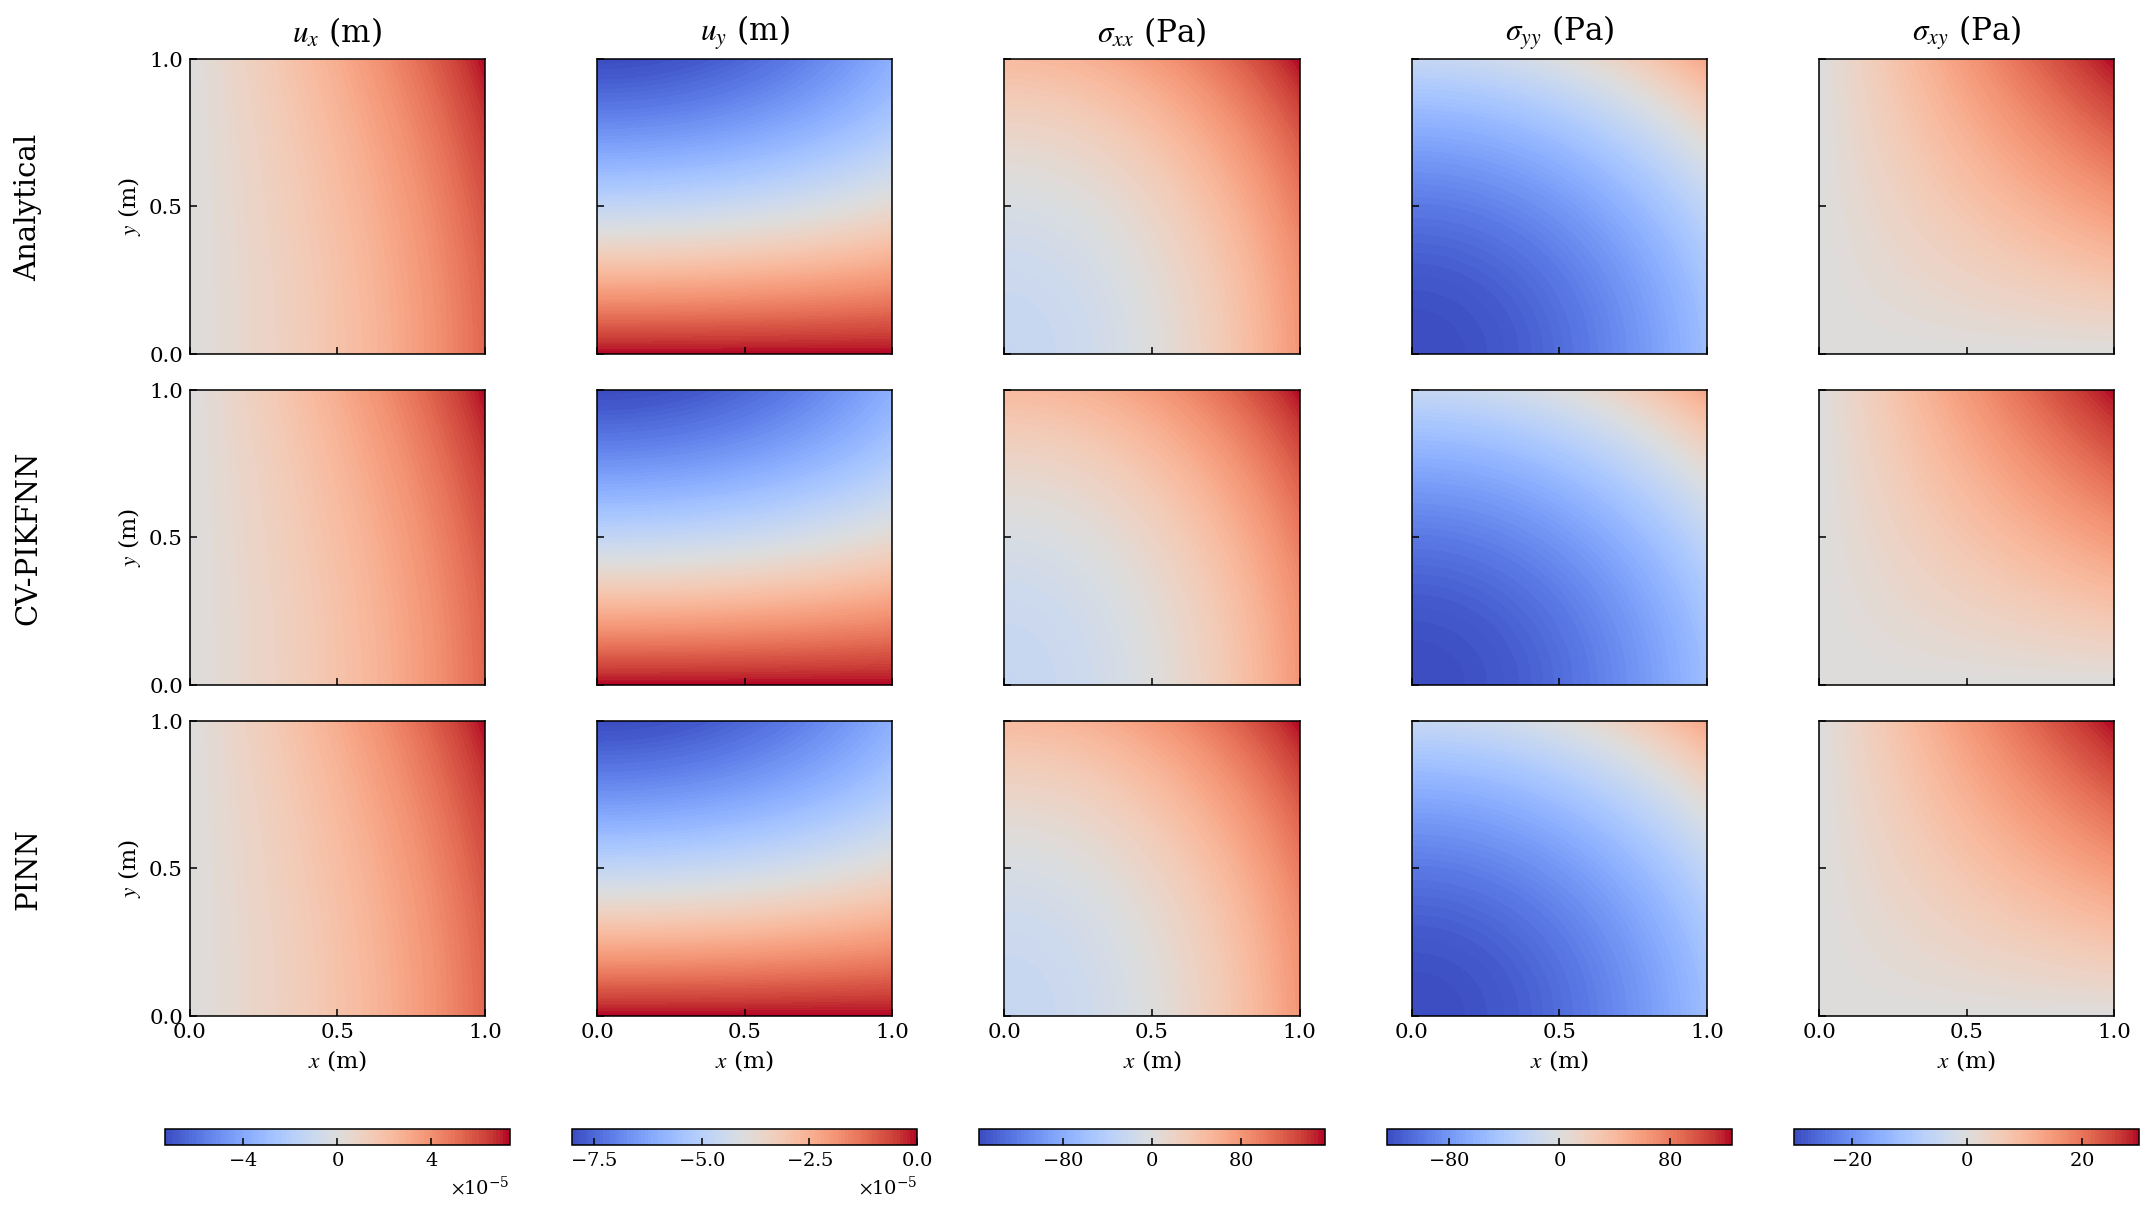

In [1]:
# 仅重绘：本单元可独立运行，不需要运行前面的配置或训练单元。
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

# 修改为你本地的结果目录；相对路径以Notebook当前工作目录为准。
pinn_results_dir = Path('square_body_force_pinn_results')
km_results_dir = Path('square_body_force_boundary_only_results')

CFG = dict(output_dir=str(pinn_results_dir), km_dir=str(km_results_dir),
           save_outputs=True, show=True)
QUANTITIES = ('ux', 'uy', 'sxx', 'syy', 'sxy')

def plot_fields(X, Y, reference, prediction, out):
    """Rows: methods; columns: ux, uy, sxx, syy, sxy. One colorbar per column."""
    from matplotlib.ticker import MaxNLocator, ScalarFormatter

    X, Y = np.asarray(X), np.asarray(Y)
    reference, prediction = np.asarray(reference), np.asarray(prediction)
    if X.shape != Y.shape or reference.shape != (X.size, 5) or prediction.shape != reference.shape:
        raise ValueError('Expected matching X/Y grids and (number_of_points, 5) field arrays.')
    fields = [reference, prediction]
    methods = ['Analytical', 'PINN']
    km_file = Path(CFG['km_dir']) / 'fields_and_coefficients.npz'
    if km_file.is_file():
        with np.load(km_file, allow_pickle=False) as data:
            needed = {'X', 'Y', 'quantities', 'reference', 'prediction'}
            compatible = needed.issubset(data.files)
            if compatible:
                compatible = (
                    data['X'].shape == X.shape and data['Y'].shape == Y.shape
                    and np.allclose(data['X'], X) and np.allclose(data['Y'], Y)
                    and np.array_equal(data['quantities'], np.array(QUANTITIES))
                    and data['reference'].shape == reference.shape
                    and data['prediction'].shape == prediction.shape
                    and np.allclose(data['reference'], reference, rtol=1e-8, atol=1e-12)
                )
            if compatible:
                fields.insert(1, data['prediction'].copy())
                methods.insert(1, 'CV-PIKFNN')
            else:
                print('KM grid/reference/quantities are incompatible; drawing a 2-by-5 comparison.')
    else:
        print('KM results not found; drawing a 2-by-5 comparison. Check CFG["km_dir"] for 3-by-5.')

    titles = (r'$u_x$ (m)', r'$u_y$ (m)', r'$\sigma_{xx}$ (Pa)',
              r'$\sigma_{yy}$ (Pa)', r'$\sigma_{xy}$ (Pa)')
    nmethods = len(fields)
    with plt.rc_context({'font.family': 'serif', 'mathtext.fontset': 'stix',
                         'font.size': 12, 'axes.titlesize': 16, 'axes.labelsize': 12}):
        fig = plt.figure(figsize=(15.5, 2.6 * nmethods + 1.55), dpi=140)
        gs = fig.add_gridspec(nmethods + 2, 5, height_ratios=[1] * nmethods + [.14, .055],
                              left=.075, right=.985, bottom=.10, top=.93,
                              wspace=.18, hspace=.19)
        axes = np.empty((nmethods, 5), dtype=object)
        for col in range(5):
            vmin = min(float(a[:, col].min()) for a in fields)
            vmax = max(float(a[:, col].max()) for a in fields)
            # Preserve the original color limits policy, shared across methods.
            if col != 1:
                vmax = max(abs(vmin), abs(vmax), 1e-30)
                vmin = -vmax
            elif vmax <= vmin:
                pad = max(abs(vmin) * .01, 1e-12)
                vmin, vmax = vmin - pad, vmax + pad
            levels = np.linspace(vmin, vmax, 101)
            for row, values in enumerate(fields):
                ax = fig.add_subplot(gs[row, col])
                axes[row, col] = ax
                im = ax.contourf(X, Y, values[:, col].reshape(X.shape),
                                 levels=levels, cmap='coolwarm')
                ax.set_aspect('equal', adjustable='box')
                ax.set_xticks(np.linspace(X.min(), X.max(), 3))
                ax.set_yticks(np.linspace(Y.min(), Y.max(), 3))
                ax.tick_params(direction='in', labelbottom=(row == nmethods - 1),
                               labelleft=(col == 0), labelsize=11)
                if row == 0:
                    ax.set_title(titles[col], pad=9)
                if row == nmethods - 1:
                    ax.set_xlabel(r'$x$ (m)', labelpad=3)
                if col == 0:
                    ax.set_ylabel(r'$y$ (m)', labelpad=3)
            cax = fig.add_subplot(gs[nmethods + 1, col])
            cb = fig.colorbar(im, cax=cax, orientation='horizontal')
            cb.locator = MaxNLocator(nbins=4)
            formatter = ScalarFormatter(useMathText=True)
            formatter.set_powerlimits((-3, 3))
            cb.formatter = formatter
            cb.update_ticks()
            cb.ax.tick_params(direction='in', labelsize=10, pad=3)
            cb.ax.xaxis.get_offset_text().set_fontsize(10)
        fig.canvas.draw()
        for row, method in enumerate(methods):
            pos = axes[row, 0].get_position()
            fig.text(.012, (pos.y0 + pos.y1) / 2, method,
                     rotation=90, ha='center', va='center', fontsize=15)
        if CFG['save_outputs']:
            out = Path(out)
            out.mkdir(parents=True, exist_ok=True)
            for ext in ('png', 'pdf'):
                target = out / f'full_field_comparison_{nmethods}x5.{ext}'
                fig.savefig(target, dpi=350, bbox_inches='tight', pad_inches=.05)
                print('Saved:', target)
    return fig


# NPZ中已经是物理单位，直接绘图，不再乘尺度。
npz_file = pinn_results_dir / 'fields_and_coefficients.npz'
if not npz_file.is_file():
    raise FileNotFoundError(f'找不到已保存的PINN结果：{npz_file.resolve()}，请修改上面的结果目录。')
with np.load(npz_file, allow_pickle=False) as saved:
    if not np.array_equal(saved['quantities'], np.array(QUANTITIES)):
        raise ValueError('结果文件的物理量顺序不匹配，不能直接重绘。')
    X, Y = saved['X'].copy(), saved['Y'].copy()
    reference, prediction = saved['reference'].copy(), saved['prediction'].copy()
plot_fields(X, Y, reference, prediction, pinn_results_dir)
plt.show()
